In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("raw_dataset.csv")
# Loads the csv file into a table called data frame
df.head()
#Shows the First 5 rows

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [48]:
print ("Shape:",df.shape )#Gives the no of rows and columns
print (df.dtypes)#Gives the data type in each coloumn
print (df.describe())#Gives averages minimum and maximum

Shape: (891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000 

In [49]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [50]:
# Percentage of missing values in each column
print((df.isnull().sum() / len(df) * 100).round(1))

# Number of fully duplicated rows
print("Duplicate rows:", df.duplicated().sum())

PassengerId     0.0
Survived        0.0
Pclass          0.0
Name            0.0
Sex             0.0
Age            19.9
SibSp           0.0
Parch           0.0
Ticket          0.0
Fare            0.0
Cabin          77.1
Embarked        0.2
dtype: float64
Duplicate rows: 0


In [51]:
df_clean = df.copy()
df_clean ["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())
df_clean ["Embarked"] = df_clean ["Embarked"].fillna (df_clean["Embarked"].mode()[0])
#fills the missing value with the most common port (mode)
#drops the column which has almost 77% missing value
df_clean = df_clean.drop(columns=["Cabin"])
print (df_clean.isnull().sum())
print("Shape after cleaning:", df_clean.shape)

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64
Shape after cleaning: (891, 11)


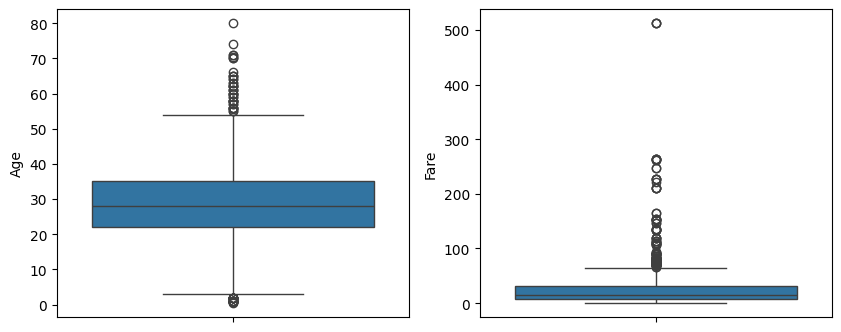

Age -> normal range: 2.5 to 54.5 | outliers: 66
Fare -> normal range: -26.7 to 65.6 | outliers: 116


In [52]:
# Box plots: dots far from the box are outliers
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df_clean["Age"], ax=axes[0])
sns.boxplot(y=df_clean["Fare"], ax=axes[1])
plt.show()

# IQR method: the "normal range" is the middle half of the data, plus some room
for col in ["Age", "Fare"]:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(col, "-> normal range:", round(lower, 1), "to", round(upper, 1), "| outliers:", count)

In [53]:
# Cap Fare outliers at the IQR fences instead of deleting rows
Q1 = df_clean["Fare"].quantile(0.25)
Q3 = df_clean["Fare"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# clip() pulls any value above/below the fences back to the fence
df_clean["Fare"] = df_clean["Fare"].clip(lower=lower, upper=upper)

print("Max Fare after capping:", df_clean["Fare"].max())
print("Shape:", df_clean.shape)

Max Fare after capping: 65.6344
Shape: (891, 11)


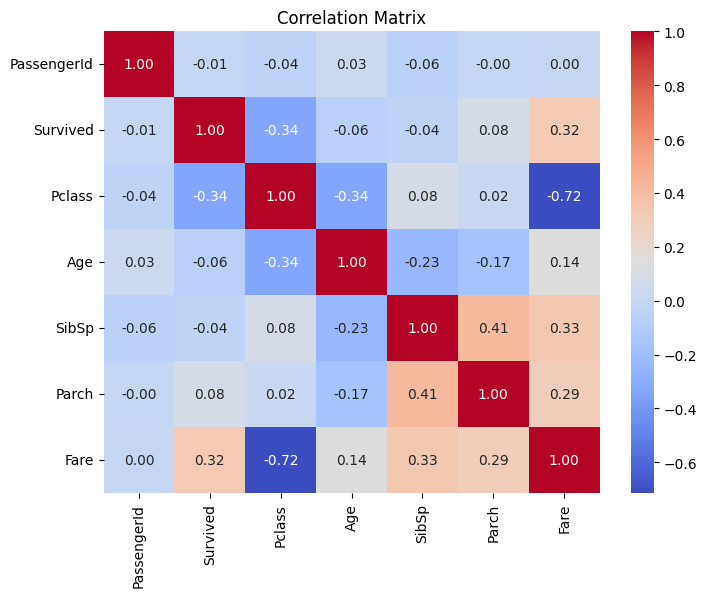

In [54]:
# Correlation heatmap: only numeric columns can be compared
plt.figure(figsize=(8, 6))
corr = df_clean.select_dtypes(include="number").corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [55]:
# Survived and Pclass are really categories (labels), not quantities
df_clean["Survived"] = df_clean["Survived"].astype("category")
df_clean["Pclass"] = df_clean["Pclass"].astype("category")
print(df_clean.dtypes)

PassengerId       int64
Survived       category
Pclass         category
Name             object
Sex              object
Age             float64
SibSp             int64
Parch             int64
Ticket           object
Fare            float64
Embarked         object
dtype: object


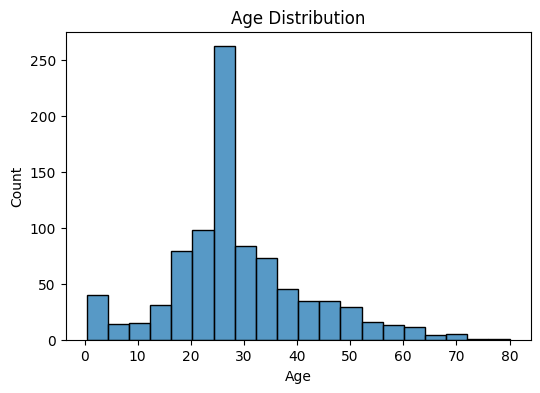

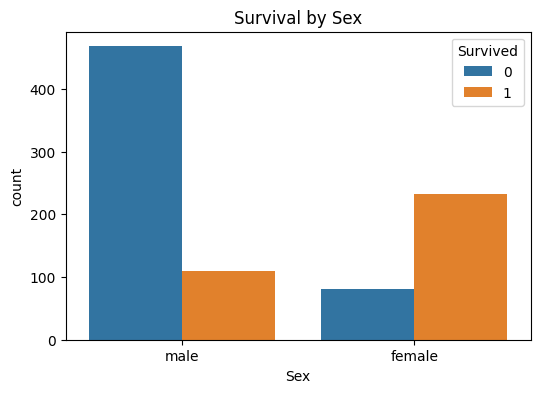

In [56]:
# How are ages spread out?
plt.figure(figsize=(6, 4))
sns.histplot(df_clean["Age"], bins=20)
plt.title("Age Distribution")
plt.show()

# Survivors vs non-survivors, split by sex
plt.figure(figsize=(6, 4))
sns.countplot(x="Sex", hue="Survived", data=df_clean)
plt.title("Survival by Sex")
plt.show()

In [57]:
# Save the cleaned table as a new CSV
df_clean.to_csv("cleaned_dataset.csv", index=False)

# Download it to your laptop
from google.colab import files
files.download("cleaned_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Above the missing-values cell: “Age (19.9%) and Embarked (0.2%) have missing values. Cabin is 77.1% empty. No duplicate rows were found.”

Above the cleaning cell: “Age was filled with the median (28), Embarked with the most common port (S), and Cabin was dropped.”

Above the outlier cell: “Fare has many outliers, so it was capped at the IQR upper limit (about 65.6). Age outliers are real ages, so they were kept.”

Under the heatmap: your 3 observations (below).

I checked these against the data. Earlier that Pclass and Fare would be about -0.5, but after capping Fare it comes out around -0.72, so by using heatmap

Pclass and Fare are strongly negatively correlated (about -0.72). First-class tickets (class 1) cost much more than third-class.

Survived and Pclass are negatively correlated (about -0.34). Passengers in higher classes survived more often: about 63% in first class, 47% in second, and 24% in third.

Survived and Fare are positively correlated (about 0.32), and SibSp and Parch move together (about 0.41). Higher fares meant better survival odds, and families tended to travel together.

The Survival by Sex chart also shows a big gap: about 74% of women survived, against about 19% of men.